# 02 · Exploratory data analysis

**Input:** `data/processed/orders_analysis.csv`, the cleaned United States order lines from notebook 01.
**Outputs:** charts in `reports/figures/`.

**Scope and conventions**
- One row is one **order line**; orders are counted as distinct Order IDs.
- Figures are **gross**: returned orders are included. The KPI notebook shows net figures.
- Lines dated after the analysis date (15 Oct 2026) are **included** and flagged, so 2026 can be compared as a full year. Every figure for October–December 2026 depends on them.
- **Margin** = total profit ÷ total sales for the group. **Average discount** = simple mean over lines (not weighted by sales).
- **Shipping Days** = Ship Date − Order Date: time to shipment, not delivery.

The last code cell recomputes every number quoted in the summary.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))
from src import cleaning as cl
from src import viz
from src.checks import Claims

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
viz.apply_style()
FIG = ROOT / "reports" / "figures"

df = cl.load_clean(ROOT / cl.ANALYSIS_FILE)
assert df["in_scope"].all(), "The analysis file should only hold in-scope (US) rows"
print("Analysis set:", df.shape)

Analysis set: (9993, 28)


## 1. Overview and coverage

In [2]:
products = df.groupby(["Product ID", "Product Name"]).ngroups
lines_per_order = df.groupby("Order ID").size()
print(f"Order lines : {len(df):,}")
print(f"Orders      : {df['Order ID'].nunique():,}  (lines per order: median {lines_per_order.median():.0f}, max {lines_per_order.max()})")
print(f"Customers   : {df['Customer ID'].nunique():,}")
print(f"Products    : {products:,} (Product ID + Product Name)")
print(f"Order dates : {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
print(f"Lines dated after {cl.REFERENCE_DATE.date()}: {df['is_future_dated'].sum():,} ({df['is_future_dated'].mean():.1%})")
print(f"Lines in returned orders: {df['is_returned'].sum():,} ({df.loc[df['is_returned'], 'Order ID'].nunique()} orders)")

by_year = df.groupby("Order Year").agg(Lines=("Sales", "size"), Orders=("Order ID", "nunique"),
                                       Customers=("Customer ID", "nunique"), Sales=("Sales", "sum"),
                                       Profit=("Profit", "sum"), Future_dated_lines=("is_future_dated", "sum"))
display(by_year.round(0))

Order lines : 9,993
Orders      : 5,009  (lines per order: median 1, max 14)
Customers   : 793
Products    : 1,894 (Product ID + Product Name)
Order dates : 2023-01-03 to 2026-12-30
Lines dated after 2026-10-15: 1,069 (10.7%)
Lines in returned orders: 800 (296 orders)


,Lines,Orders,Customers,Sales,Profit,Future_dated_lines
Order Year,,,,,,
2023,1992,969,595,483966.0,49556.0,0
2024,2102,1038,573,470533.0,61619.0,0
2025,2587,1315,638,609206.0,81795.0,0
2026,3312,1687,693,733215.0,93439.0,1069


## 2. Distributions

,Sales,Quantity,Discount,Profit,Shipping Days
count,9993.00,9993.00,9993.00,9993.00,9993.00
mean,229.85,3.79,0.16,28.66,3.96
std,623.28,2.23,0.21,234.27,1.75
min,0.44,1.00,0.00,-6599.98,0.00
25%,17.28,2.00,0.00,1.73,3.00
50%,54.48,3.00,0.20,8.67,4.00
75%,209.94,5.00,0.20,29.36,5.00
max,22638.48,14.00,0.80,8399.98,7.00


Skewness: {'Sales': 12.97, 'Quantity': 1.28, 'Discount': 1.68, 'Profit': 7.56}
Discount levels used: [np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


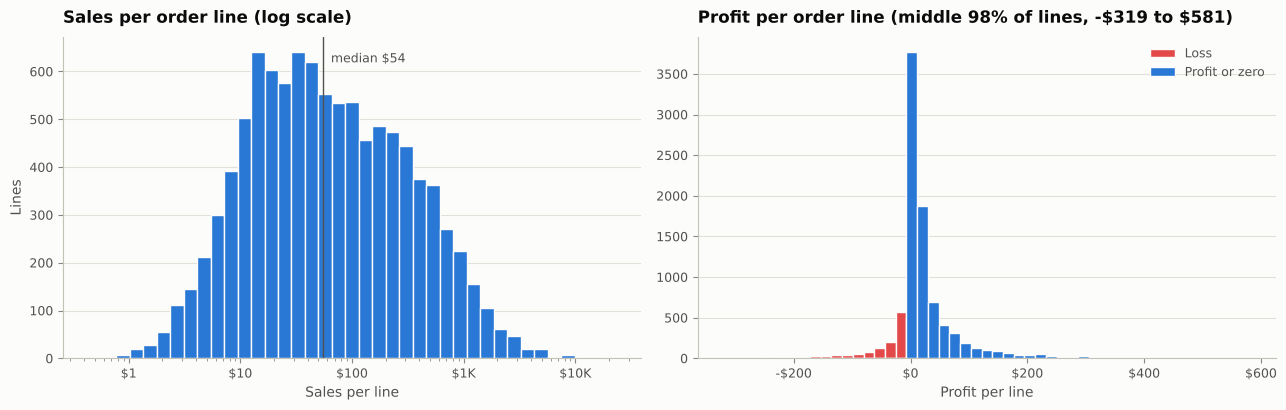

In [3]:
display(df[["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]].describe().round(2))
print("Skewness:", df[["Sales", "Quantity", "Discount", "Profit"]].skew().round(2).to_dict())
print("Discount levels used:", sorted(df["Discount"].unique()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.hist(df["Sales"], bins=np.logspace(np.log10(df["Sales"].min()), np.log10(df["Sales"].max()), 40),
        color=viz.SALES, edgecolor=viz.SURFACE, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(viz.money_axis)
ax.axvline(df["Sales"].median(), color=viz.INK_2, linewidth=1)
ax.annotate(f"median {viz.money(df['Sales'].median())}", (df["Sales"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=viz.INK_2, fontsize=9)
ax.set_title("Sales per order line (log scale)")
ax.set_xlabel("Sales per line")
ax.set_ylabel("Lines")
viz.value_grid_only(ax, "y")

ax = axes[1]
lo, hi = df["Profit"].quantile([0.01, 0.99])
middle = df.loc[df["Profit"].between(lo, hi), "Profit"]          # tails left out, not clipped
bins = np.linspace(lo, hi, 50)
ax.hist(middle[middle < 0], bins=bins, color=viz.LOSS, edgecolor=viz.SURFACE, linewidth=1, label="Loss")
ax.hist(middle[middle >= 0], bins=bins, color=viz.GAIN, edgecolor=viz.SURFACE, linewidth=1, label="Profit or zero")
ax.xaxis.set_major_formatter(viz.money_axis)
ax.set_title(f"Profit per order line (middle 98% of lines, {viz.money(lo)} to {viz.money(hi)})")
ax.set_xlabel("Profit per line")
ax.legend(loc="upper right")
viz.value_grid_only(ax, "y")
fig.tight_layout()
viz.save(fig, "01_line_distributions", FIG)
plt.show()

## 3. Headline numbers

In [4]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
print(f"Total sales  : ${total_sales:,.0f}")
print(f"Total profit : ${total_profit:,.0f}  (margin {total_profit / total_sales:.1%})")
print(f"Loss-making lines: {(df['Profit'] < 0).sum():,} ({(df['Profit'] < 0).mean():.1%}); zero-profit lines: {(df['Profit'] == 0).sum()}")
print(f"Sales per line: median ${df['Sales'].median():,.2f} vs mean ${df['Sales'].mean():,.2f}")

Total sales  : $2,296,919
Total profit : $286,409  (margin 12.5%)
Loss-making lines: 1,870 (18.7%); zero-profit lines: 65
Sales per line: median $54.48 vs mean $229.85


## 4. Categories

,Sales,Profit,Margin %,Sales share %,Profit share %
Category,,,,,
Technology,836154.0,145454.9,17.4,36.4,50.8
Furniture,741718.4,18463.3,2.5,32.3,6.4
Office Supplies,719047.0,122490.8,17.0,31.3,42.8


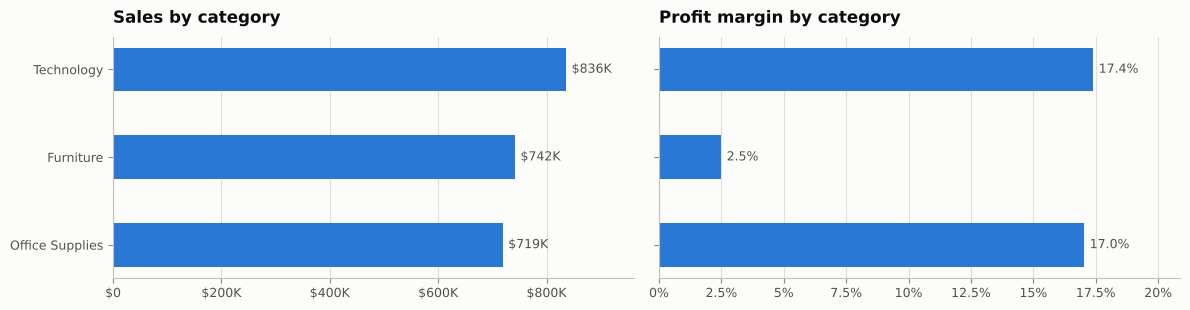

In [5]:
cat = df.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100
cat["Sales share %"] = cat["Sales"] / cat["Sales"].sum() * 100
cat["Profit share %"] = cat["Profit"] / cat["Profit"].sum() * 100
cat = cat.sort_values("Sales")
display(cat.sort_values("Sales", ascending=False).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
y = np.arange(len(cat))
axes[0].barh(y, cat["Sales"], height=0.5, color=viz.SALES)
for yi, v in zip(y, cat["Sales"]):
    axes[0].annotate(viz.money(v), (v, yi), xytext=(4, 0), textcoords="offset points", va="center", color=viz.INK_2, fontsize=9)
axes[0].set_title("Sales by category")
axes[0].xaxis.set_major_formatter(viz.money_axis)
axes[0].set_xlim(0, cat["Sales"].max() * 1.15)
axes[1].barh(y, cat["Margin %"], height=0.5, color=viz.SALES)
for yi, v in zip(y, cat["Margin %"]):
    axes[1].annotate(f"{v:.1f}%", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", color=viz.INK_2, fontsize=9)
axes[1].set_title("Profit margin by category")
axes[1].xaxis.set_major_formatter(viz.pct_axis)
axes[1].set_xlim(0, cat["Margin %"].max() * 1.2)
axes[0].set_yticks(y, cat.index)
for ax in axes:
    viz.value_grid_only(ax, "x")
fig.tight_layout()
viz.save(fig, "02_category_sales_margin", FIG)
plt.show()

## 5. Monthly trend

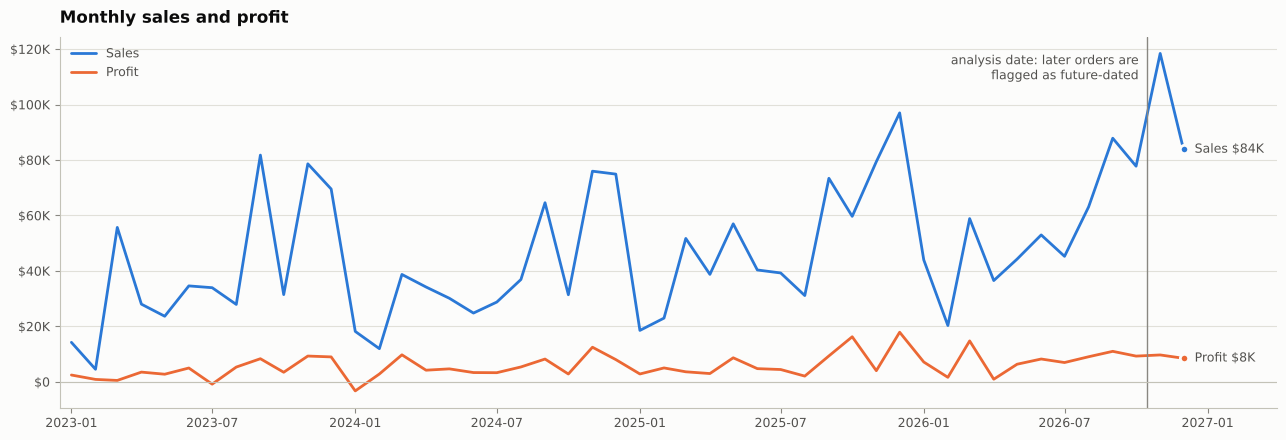

In [6]:
monthly = df.groupby("Order Month")[["Sales", "Profit"]].sum()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly.index, monthly["Sales"], color=viz.SALES, label="Sales")
ax.plot(monthly.index, monthly["Profit"], color=viz.PROFIT, label="Profit")
for col, color in [("Sales", viz.SALES), ("Profit", viz.PROFIT)]:
    ax.plot(monthly.index[-1], monthly[col].iloc[-1], "o", color=color, markersize=6, markeredgecolor=viz.SURFACE, markeredgewidth=2)
    ax.annotate(f"{col} {viz.money(monthly[col].iloc[-1])}", (monthly.index[-1], monthly[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=viz.INK_2, fontsize=9)
ax.axvline(cl.REFERENCE_DATE, color=viz.MUTED, linewidth=1)
ax.annotate("analysis date: later orders are\nflagged as future-dated", (cl.REFERENCE_DATE, monthly["Sales"].max()),
            xytext=(-6, 0), textcoords="offset points", ha="right", va="top", color=viz.INK_2, fontsize=9)
ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.yaxis.set_major_formatter(viz.money_axis)
ax.set_title("Monthly sales and profit")
ax.legend(loc="upper left")
ax.set_xlim(monthly.index.min() - pd.Timedelta(days=15), monthly.index.max() + pd.Timedelta(days=120))
viz.value_grid_only(ax, "y")
fig.tight_layout()
viz.save(fig, "03_monthly_trend", FIG)
plt.show()

## 6. Seasonality: sales versus profit by month and year

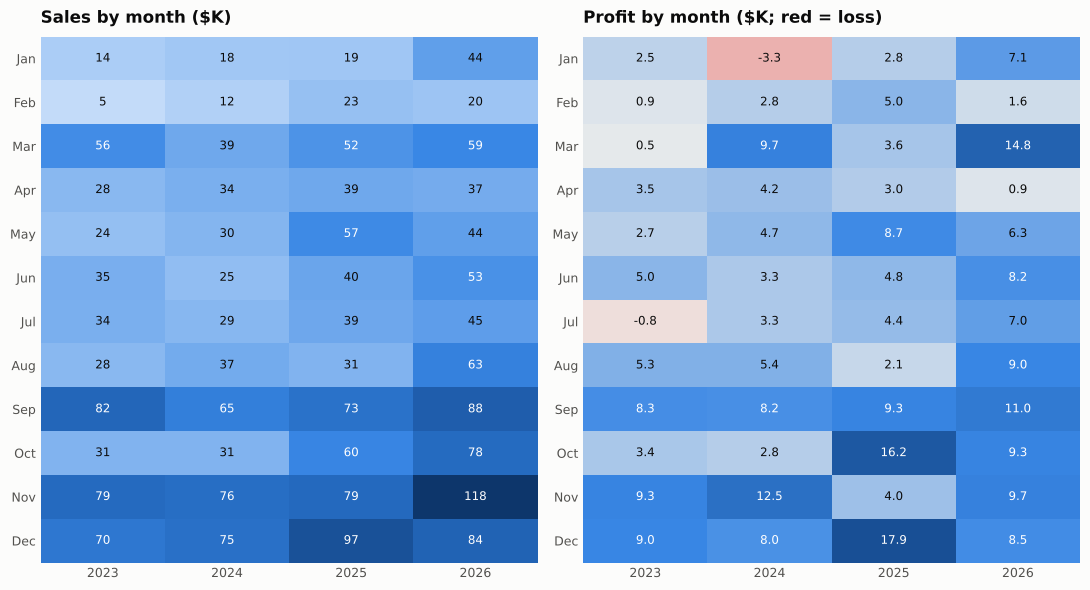

Top-3 months by SALES  : {2023: [9, 11, 12], 2024: [9, 11, 12], 2025: [9, 11, 12], 2026: [9, 11, 12]}
Top-3 months by PROFIT : {2023: [9, 11, 12], 2024: [3, 9, 11], 2025: [9, 10, 12], 2026: [3, 9, 11]}
Sep-Dec share of annual SALES  : {2023: 0.54, 2024: 0.525, 2025: 0.508, 2026: 0.502}
Sep-Dec share of annual PROFIT : {2023: 0.606, 2024: 0.512, 2025: 0.58, 2026: 0.411}
October sales rank (1 = best)  : {2023: 7, 2024: 7, 2025: 4, 2026: 4}


In [7]:
month = df["Order Date"].dt.month.rename("Month")
sales_pv = df.pivot_table(index=month, columns="Order Year", values="Sales", aggfunc="sum")
profit_pv = df.pivot_table(index=month, columns="Order Year", values="Profit", aggfunc="sum")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def heat(ax, table, cmap, title, center=None, fmt="{:.0f}"):
    values = table.to_numpy() / 1000
    if center is None:
        vmin, vmax = 0, values.max()
    else:
        lim = np.abs(values).max()
        vmin, vmax = -lim, lim
    im = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(values):
        r, g, b, _ = im.cmap(im.norm(v))
        ink = "white" if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else viz.INK
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5, color=ink)
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(12), month_names)
    ax.set_title(title)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
heat(axes[0], sales_pv, viz.SEQUENTIAL, "Sales by month ($K)")
heat(axes[1], profit_pv, viz.DIVERGING, "Profit by month ($K; red = loss)", center=0, fmt="{:.1f}")
fig.tight_layout()
viz.save(fig, "04_seasonality", FIG)
plt.show()

top_sales = {y: sorted(sales_pv[y].nlargest(3).index.tolist()) for y in sales_pv.columns}
top_profit = {y: sorted(profit_pv[y].nlargest(3).index.tolist()) for y in profit_pv.columns}
print("Top-3 months by SALES  :", top_sales)
print("Top-3 months by PROFIT :", top_profit)
print("Sep-Dec share of annual SALES  :", (sales_pv.loc[9:12].sum() / sales_pv.sum()).round(3).to_dict())
print("Sep-Dec share of annual PROFIT :", (profit_pv.loc[9:12].sum() / profit_pv.sum()).round(3).to_dict())
print("October sales rank (1 = best)  :", sales_pv.rank(ascending=False).loc[10].astype(int).to_dict())

## 7. Sub-categories

,Sales,Profit,Quantity,Avg_discount,Margin %,Sales rank
Sub-Category,,,,,,
Phones,330007.0,44516.0,3289,0.155,13.5,1
Chairs,328168.0,26602.0,2354,0.170,8.1,2
Storage,223844.0,21279.0,3158,0.075,9.5,3
Tables,206966.0,-17725.0,1241,0.261,-8.6,4
Binders,203413.0,30222.0,5974,0.372,14.9,5
Machines,189239.0,3385.0,440,0.306,1.8,6
Accessories,167380.0,41937.0,2976,0.078,25.1,7
Copiers,149528.0,55618.0,234,0.162,37.2,8
Bookcases,114880.0,-3473.0,868,0.211,-3.0,9


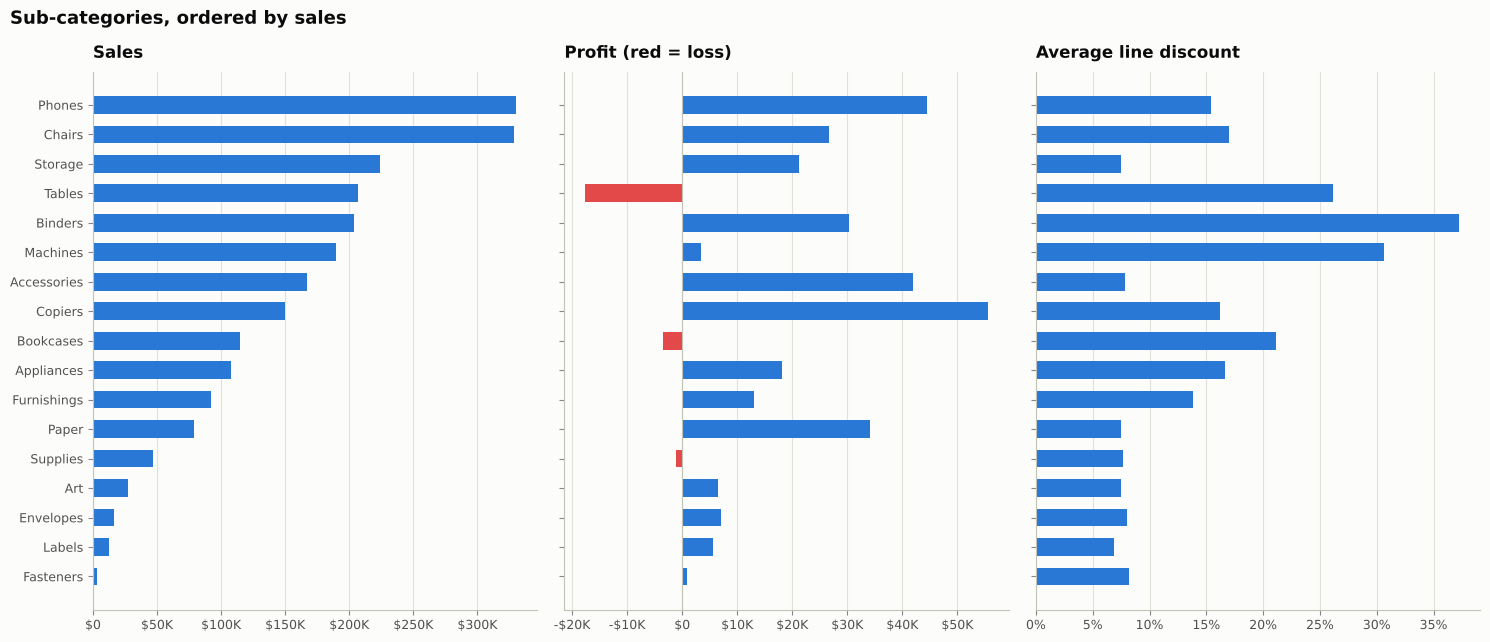

In [8]:
sub = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                     Quantity=("Quantity", "sum"), Avg_discount=("Discount", "mean"))
sub["Margin %"] = sub["Profit"] / sub["Sales"] * 100
sub["Sales rank"] = sub["Sales"].rank(ascending=False).astype(int)
sub = sub.sort_values("Sales", ascending=False)
display(sub.round({"Sales": 0, "Profit": 0, "Avg_discount": 3, "Margin %": 1}))

order = sub.index[::-1]
y = np.arange(len(order))
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
axes[0].barh(y, sub.loc[order, "Sales"], height=0.6, color=viz.SALES)
axes[0].set_title("Sales")
axes[0].xaxis.set_major_formatter(viz.money_axis)
p = sub.loc[order, "Profit"]
axes[1].barh(y, p, height=0.6, color=np.where(p < 0, viz.LOSS, viz.GAIN))
axes[1].axvline(0, color=viz.AXIS, linewidth=0.8)
axes[1].set_title("Profit (red = loss)")
axes[1].xaxis.set_major_formatter(viz.money_axis)
axes[2].barh(y, sub.loc[order, "Avg_discount"] * 100, height=0.6, color=viz.SALES)
axes[2].set_title("Average line discount")
axes[2].xaxis.set_major_formatter(viz.pct_axis)
axes[0].set_yticks(y, order)
for ax in axes:
    viz.value_grid_only(ax, "x")
fig.suptitle("Sub-categories, ordered by sales", x=0.01, ha="left", color=viz.INK, fontsize=13, fontweight="bold")
fig.tight_layout()
viz.save(fig, "05_subcategories", FIG)
plt.show()

## 8. Discounts and profit

,Lines,Sales,Profit,Margin %
Discount,,,,
0.00,4798,1087908.0,320988.0,29.5
0.10,94,54369.0,9029.0,16.6
0.15,52,27559.0,1419.0,5.1
0.20,3657,764594.0,90337.0,11.8
0.30,226,102945.0,-10357.0,-10.1
0.32,27,14493.0,-2391.0,-16.5
0.40,206,116418.0,-23057.0,-19.8
0.45,11,5485.0,-2493.0,-45.5
0.50,66,58919.0,-20506.0,-34.8


Discount vs profit per line -> Pearson -0.22 | Spearman -0.54
Lines discounted 30% or more: 1,392 (13.9%), profit $-135,364
All other lines: profit $421,773 (actual total $286,409)
Average line discount by region: {'Central': 0.24, 'East': 0.145, 'South': 0.147, 'West': 0.109}

Binders discount levels (lines): {0.0: 337, 0.2: 573, 0.7: 380, 0.8: 233}
  0-20% discount: 910 lines, sales $167,272, profit $68,732, margin 41.1%
  70-80% discount: 613 lines, sales $36,141, profit $-38,510, margin -106.6%


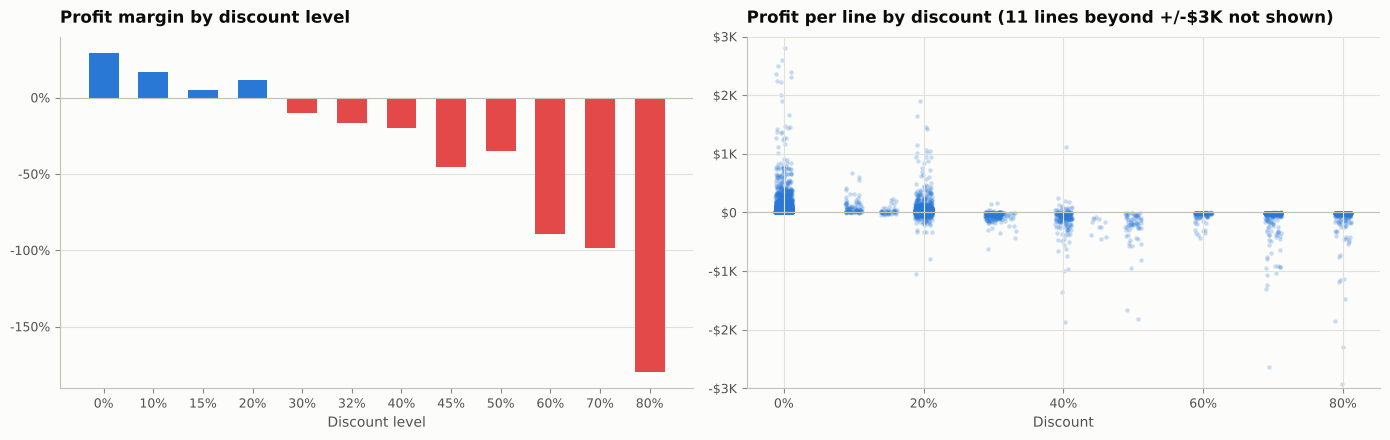

In [9]:
lvl = df.groupby("Discount").agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
lvl["Margin %"] = lvl["Profit"] / lvl["Sales"] * 100
display(lvl.round({"Sales": 0, "Profit": 0, "Margin %": 1}))

pearson = df["Discount"].corr(df["Profit"])
spearman = df["Discount"].rank().corr(df["Profit"].rank())    # Spearman = Pearson on ranks
print(f"Discount vs profit per line -> Pearson {pearson:.2f} | Spearman {spearman:.2f}")

deep = df["Discount"] >= 0.3
print(f"Lines discounted 30% or more: {deep.sum():,} ({deep.mean():.1%}), profit ${df.loc[deep, 'Profit'].sum():,.0f}")
print(f"All other lines: profit ${df.loc[~deep, 'Profit'].sum():,.0f} (actual total ${df['Profit'].sum():,.0f})")
print("Average line discount by region:", df.groupby("Region")["Discount"].mean().round(3).to_dict())

b = df[df["Sub-Category"] == "Binders"]
b_deep = b["Discount"] >= 0.5
print("\nBinders discount levels (lines):", b["Discount"].value_counts().sort_index().to_dict())
for label, grp in [("0-20% discount", b[~b_deep]), ("70-80% discount", b[b_deep])]:
    print(f"  {label}: {len(grp):,} lines, sales ${grp['Sales'].sum():,.0f}, profit ${grp['Profit'].sum():,.0f}, "
          f"margin {grp['Profit'].sum() / grp['Sales'].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
x = np.arange(len(lvl))
ax.bar(x, lvl["Margin %"], width=0.6, color=np.where(lvl["Margin %"] < 0, viz.LOSS, viz.GAIN))
ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x, [f"{d:.0%}" for d in lvl.index])
ax.yaxis.set_major_formatter(viz.pct_axis)
ax.set_xlabel("Discount level")
ax.set_title("Profit margin by discount level")
viz.value_grid_only(ax, "y")

ax = axes[1]
jitter = np.random.default_rng(0).uniform(-0.012, 0.012, len(df))
ax.scatter(df["Discount"] + jitter, df["Profit"], s=10, alpha=0.25, color=viz.SALES, linewidths=0)
ax.set_ylim(-3000, 3000)
outside = int((df["Profit"].abs() > 3000).sum())
ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(viz.money_axis)
ax.set_xlabel("Discount")
ax.set_title(f"Profit per line by discount ({outside} lines beyond +/-$3K not shown)")
fig.tight_layout()
viz.save(fig, "06_discount_margin", FIG)
plt.show()

## 9. Regions and customer segments

,Sales,Profit,Orders,Avg_discount,Margin %,Sales share %,Profit share %
Region,,,,,,,
West,725458.0,108418.0,1611,0.109,14.9,31.6,37.9
East,678500.0,91535.0,1401,0.145,13.5,29.5,32.0
Central,501240.0,39706.0,1175,0.240,7.9,21.8,13.9
South,391722.0,46749.0,822,0.147,11.9,17.1,16.3


,Sales,Profit,Orders,Avg_discount,Margin %,Sales share %,Profit share %
Segment,,,,,,,
Consumer,1161401.0,134119.0,2586,0.158,11.5,50.6,46.8
Corporate,706146.0,91979.0,1514,0.158,13.0,30.7,32.1
Home Office,429372.0,60311.0,909,0.147,14.0,18.7,21.1


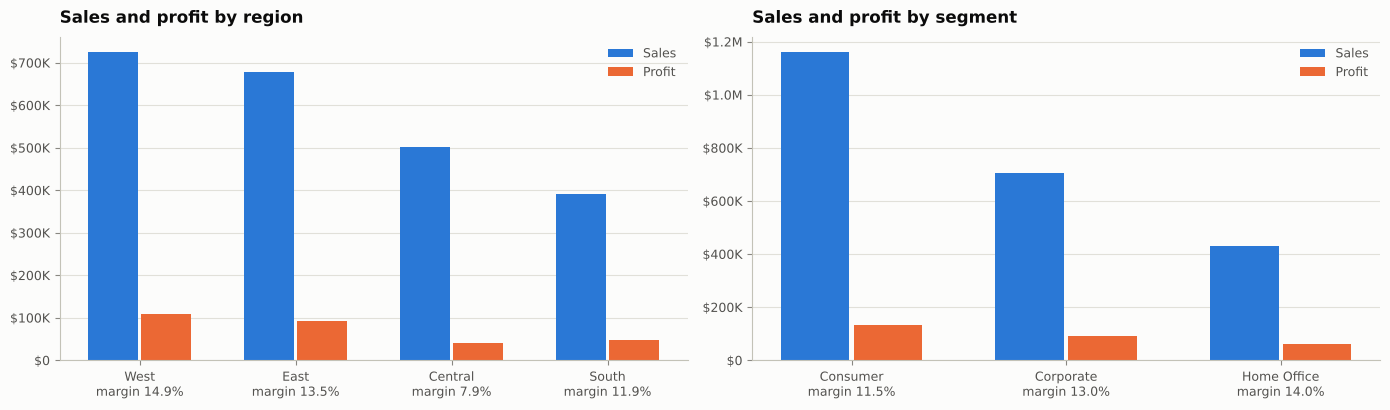

In [10]:
def group_table(col):
    t = df.groupby(col).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"),
                            Avg_discount=("Discount", "mean"))
    t["Margin %"] = t["Profit"] / t["Sales"] * 100
    t["Sales share %"] = t["Sales"] / t["Sales"].sum() * 100
    t["Profit share %"] = t["Profit"] / t["Profit"].sum() * 100
    return t.sort_values("Sales", ascending=False)

rg, sg = group_table("Region"), group_table("Segment")
display(rg.round({"Sales": 0, "Profit": 0, "Avg_discount": 3, "Margin %": 1, "Sales share %": 1, "Profit share %": 1}))
display(sg.round({"Sales": 0, "Profit": 0, "Avg_discount": 3, "Margin %": 1, "Sales share %": 1, "Profit share %": 1}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, t, title in [(axes[0], rg, "Sales and profit by region"), (axes[1], sg, "Sales and profit by segment")]:
    x = np.arange(len(t))
    ax.bar(x - 0.17, t["Sales"], width=0.32, color=viz.SALES, label="Sales")
    ax.bar(x + 0.17, t["Profit"], width=0.32, color=viz.PROFIT, label="Profit")
    ax.set_xticks(x, [f"{n}\nmargin {m:.1f}%" for n, m in zip(t.index, t["Margin %"])])
    ax.yaxis.set_major_formatter(viz.money_axis)
    ax.set_title(title)
    ax.legend(loc="upper right")
    viz.value_grid_only(ax, "y")
fig.tight_layout()
viz.save(fig, "07_region_segment", FIG)
plt.show()

## 10. Shipping times (order to shipment)

,count,mean,min,max
Ship Mode,,,,
Same Day,543,0.04,0,1
First Class,1538,2.18,1,4
Second Class,1945,3.24,1,5
Standard Class,5967,5.01,3,7


Same Day shipped on the order date : 95.6%
First Class shipped within 1-2 days: 59.5%
Standard Class outside 4-7 days    : 1 lines


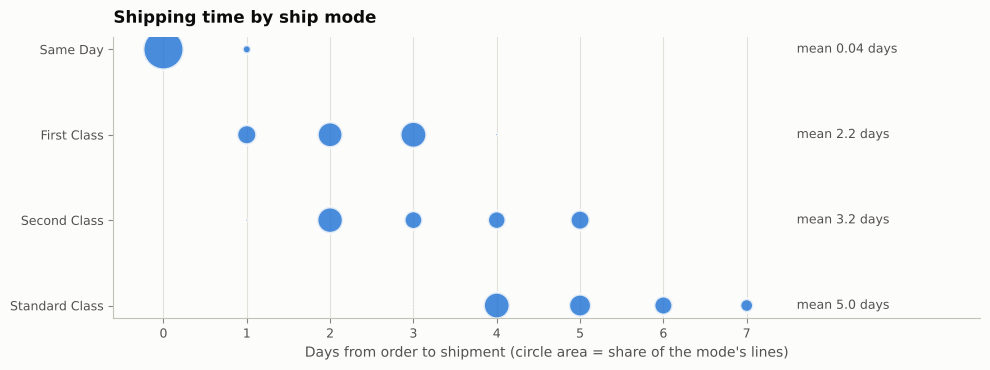

In [11]:
modes = ["Same Day", "First Class", "Second Class", "Standard Class"]
ship = df.groupby("Ship Mode")["Shipping Days"].agg(["count", "mean", "min", "max"]).reindex(modes)
display(ship.round(2))
print("Same Day shipped on the order date : %.1f%%" % ((df.loc[df["Ship Mode"] == "Same Day", "Shipping Days"] == 0).mean() * 100))
print("First Class shipped within 1-2 days: %.1f%%" % (df.loc[df["Ship Mode"] == "First Class", "Shipping Days"].between(1, 2).mean() * 100))
std_days = df.loc[df["Ship Mode"] == "Standard Class", "Shipping Days"]
print("Standard Class outside 4-7 days    : %d lines" % (~std_days.between(4, 7)).sum())

fig, ax = plt.subplots(figsize=(10, 3.8))
dist = (df.groupby(["Ship Mode", "Shipping Days"]).size() / df.groupby("Ship Mode").size()).unstack(fill_value=0).reindex(modes) * 100
for i, m in enumerate(modes):
    row = dist.loc[m]
    row = row[row > 0]
    ax.scatter(row.index, [i] * len(row), s=row.to_numpy() * 9, color=viz.SALES, alpha=0.85, edgecolors=viz.SURFACE, linewidths=2)
    mean = ship.loc[m, "mean"]
    ax.annotate(f"mean {mean:.2f} days" if mean < 1 else f"mean {mean:.1f} days", (dist.columns.max() + 0.6, i), va="center", color=viz.INK_2, fontsize=9)
ax.set_yticks(range(len(modes)), modes)
ax.invert_yaxis()
ax.set_xticks(dist.columns)
ax.set_xlim(-0.6, dist.columns.max() + 2.8)
ax.set_xlabel("Days from order to shipment (circle area = share of the mode's lines)")
ax.set_title("Shipping time by ship mode")
viz.value_grid_only(ax, "x")
fig.tight_layout()
viz.save(fig, "08_shipping_days", FIG)
plt.show()

## 11. Claim verification

In [12]:
c = Claims()
ts, tp = df["Sales"].sum(), df["Profit"].sum()

# Overview and headline
c.check("9,993 lines, 5,009 orders, 793 customers, 1,894 products", (len(df), df["Order ID"].nunique(), df["Customer ID"].nunique(), products) == (9993, 5009, 793, 1894),
        (len(df), df["Order ID"].nunique(), df["Customer ID"].nunique(), products))
c.check("1,069 lines dated after 15 Oct 2026", int(df["is_future_dated"].sum()) == 1069, int(df["is_future_dated"].sum()))
c.check("Sales $2.30M, profit $286K, margin 12.5%", (round(ts / 1e6, 2), round(tp / 1e3), round(tp / ts * 100, 1)) == (2.30, 286, 12.5), (round(ts, 2), round(tp, 2), round(tp / ts * 100, 2)))
c.check("1,870 loss-making lines (18.7%)", (int((df["Profit"] < 0).sum()), round((df["Profit"] < 0).mean() * 100, 1)) == (1870, 18.7), int((df["Profit"] < 0).sum()))
c.check("Sales per line: median $54, mean $230", (round(df["Sales"].median()), round(df["Sales"].mean())) == (54, 230), (round(df["Sales"].median(), 2), round(df["Sales"].mean(), 2)))
c.check("Sales skewness about 13", round(df["Sales"].skew()) == 13, round(df["Sales"].skew(), 2))

# Categories
k = cat
c.check("Technology $836K / 17.4%; Furniture $742K / 2.5%; Office Supplies $719K / 17.0%",
        [(round(k.loc[n, "Sales"] / 1e3), round(k.loc[n, "Margin %"], 1)) for n in ["Technology", "Furniture", "Office Supplies"]] == [(836, 17.4), (742, 2.5), (719, 17.0)],
        k[["Sales", "Margin %"]].round(1).to_dict("index"))
c.check("Furniture: 2nd in sales but 6.4% of profit", (int(k["Sales"].rank(ascending=False)["Furniture"]), round(k.loc["Furniture", "Profit share %"], 1)) == (2, 6.4),
        round(k.loc["Furniture", "Profit share %"], 2))

# Seasonality
sh_s = sales_pv.loc[9:12].sum() / sales_pv.sum()
sh_p = profit_pv.loc[9:12].sum() / profit_pv.sum()
oct_rank = sales_pv.rank(ascending=False).loc[10].astype(int).to_dict()
c.check("Sep, Nov and Dec are the top-3 sales months in every year", all(v == [9, 11, 12] for v in top_sales.values()), top_sales)
c.check("Sep-Dec = 50-54% of annual sales", (round(sh_s.min() * 100), round(sh_s.max() * 100)) == (50, 54), sh_s.round(3).to_dict())
c.check("October sales rank: 7th in 2023-2024, 4th in 2025-2026", oct_rank == {2023: 7, 2024: 7, 2025: 4, 2026: 4}, oct_rank)
c.check("September is the only month in the profit top 3 every year", set.intersection(*[set(v) for v in top_profit.values()]) == {9}, top_profit)
c.check("March is a top-3 profit month in 2024 and 2026", 3 in top_profit[2024] and 3 in top_profit[2026], top_profit)
c.check("Sep-Dec share of annual profit ranges from 41% to 61%", (round(sh_p.min() * 100), round(sh_p.max() * 100)) == (41, 61), sh_p.round(3).to_dict())

# Sub-categories
def row(n):
    r = sub.loc[n]
    return (round(r["Sales"] / 1e3), int(r["Sales rank"]), round(r["Profit"] / 1e3, 1), round(r["Margin %"], 1), round(r["Avg_discount"] * 100, 1))
c.check("Only Tables, Bookcases and Supplies lose money", sorted(sub.index[sub["Profit"] < 0]) == ["Bookcases", "Supplies", "Tables"], sorted(sub.index[sub["Profit"] < 0]))
c.check("Tables: $207K sales (rank 4), -$17.7K profit, -8.6% margin, 26.1% avg discount", row("Tables") == (207, 4, -17.7, -8.6, 26.1), row("Tables"))
c.check("Bookcases: $115K sales (rank 9), -$3.5K profit, -3.0% margin", row("Bookcases")[:4] == (115, 9, -3.5, -3.0), row("Bookcases"))
c.check("Supplies: $47K sales (rank 13 of 17), -$1.2K profit, -2.5% margin", len(sub) == 17 and row("Supplies")[:4] == (47, 13, -1.2, -2.5), row("Supplies"))
c.check("Machines: $189K sales, 1.8% margin, 30.6% avg discount", (row("Machines")[0], row("Machines")[3], row("Machines")[4]) == (189, 1.8, 30.6), row("Machines"))
c.check("Copiers: rank 8 in sales ($150K) but the most profit ($55.6K, 37.2% margin)",
        (row("Copiers")[:4], sub["Profit"].idxmax()) == ((150, 8, 55.6, 37.2), "Copiers"), (row("Copiers"), sub["Profit"].idxmax()))
c.check("Binders: highest avg discount (37.2%) yet 14.9% margin and $30K profit",
        sub["Avg_discount"].idxmax() == "Binders" and (row("Binders")[4], row("Binders")[3], round(sub.loc["Binders", "Profit"] / 1e3)) == (37.2, 14.9, 30), row("Binders"))

# Discounts
mb_lo = b.loc[~b_deep, "Profit"].sum() / b.loc[~b_deep, "Sales"].sum() * 100
mb_hi = b.loc[b_deep, "Profit"].sum() / b.loc[b_deep, "Sales"].sum() * 100
c.check("Discount vs profit: Pearson -0.22, Spearman -0.54", (round(pearson, 2), round(spearman, 2)) == (-0.22, -0.54), (round(pearson, 3), round(spearman, 3)))
c.check("Margin 29.5% with no discount", round(lvl.loc[0.0, "Margin %"], 1) == 29.5, round(lvl.loc[0.0, "Margin %"], 2))
c.check("Margin positive at every discount level up to 20%, negative at every level of 30% or more",
        (lvl.loc[lvl.index <= 0.2, "Margin %"] > 0).all() and (lvl.loc[lvl.index >= 0.3, "Margin %"] < 0).all(), lvl["Margin %"].round(1).to_dict())
c.check("Lines discounted >= 30%: 13.9% of lines, -$135K profit; all other lines earn $422K",
        (round(deep.mean() * 100, 1), round(df.loc[deep, "Profit"].sum() / 1e3), round(df.loc[~deep, "Profit"].sum() / 1e3)) == (13.9, -135, 422),
        (round(deep.mean() * 100, 2), round(df.loc[deep, "Profit"].sum()), round(df.loc[~deep, "Profit"].sum())))
c.check("Binders: 910 lines at 0-20% discount (41.1% margin) vs 613 lines at 70-80% (-106.6% margin)",
        (int((~b_deep).sum()), int(b_deep.sum()), round(mb_lo, 1), round(mb_hi, 1)) == (910, 613, 41.1, -106.6) and set(b["Discount"].unique()) == {0.0, 0.2, 0.7, 0.8},
        (int((~b_deep).sum()), int(b_deep.sum()), round(mb_lo, 2), round(mb_hi, 2)))

# Regions and segments
we = ["West", "East"]
c.check("West + East = 61.1% of sales and 69.8% of profit", (round(rg.loc[we, "Sales share %"].sum(), 1), round(rg.loc[we, "Profit share %"].sum(), 1)) == (61.1, 69.8),
        (round(rg.loc[we, "Sales share %"].sum(), 2), round(rg.loc[we, "Profit share %"].sum(), 2)))
c.check("Central: 3rd in sales ($501K), lowest margin (7.9%), highest avg discount (24.0%)",
        list(rg.index).index("Central") == 2 and round(rg.loc["Central", "Sales"] / 1e3) == 501 and rg["Margin %"].idxmin() == "Central"
        and round(rg.loc["Central", "Margin %"], 1) == 7.9 and rg["Avg_discount"].idxmax() == "Central" and round(rg.loc["Central", "Avg_discount"] * 100, 1) == 24.0,
        rg[["Sales", "Margin %", "Avg_discount"]].round(3).to_dict("index"))
c.check("Central profit $39.7K is below South $46.7K (South sales $392K)",
        (round(rg.loc["Central", "Profit"] / 1e3, 1), round(rg.loc["South", "Profit"] / 1e3, 1), round(rg.loc["South", "Sales"] / 1e3)) == (39.7, 46.7, 392), rg["Profit"].round(0).to_dict())
c.check("Consumer: 50.6% of sales, 11.5% margin; Corporate 13.0%; Home Office 14.0%",
        (round(sg.loc["Consumer", "Sales share %"], 1), round(sg.loc["Consumer", "Margin %"], 1), round(sg.loc["Corporate", "Margin %"], 1), round(sg.loc["Home Office", "Margin %"], 1)) == (50.6, 11.5, 13.0, 14.0),
        sg[["Sales share %", "Margin %"]].round(2).to_dict("index"))

# Shipping
sday = df.loc[df["Ship Mode"] == "Same Day", "Shipping Days"]
fcl = df.loc[df["Ship Mode"] == "First Class", "Shipping Days"]
c.check("Same Day: mean 0.04 days, 95.6% on the order date, max 1 day", (round(sday.mean(), 2), round((sday == 0).mean() * 100, 1), sday.max()) == (0.04, 95.6, 1), (round(sday.mean(), 3), round((sday == 0).mean() * 100, 2), sday.max()))
c.check("First Class: mean 2.2 days (1-4), 59.5% within 1-2 days", (round(fcl.mean(), 1), fcl.min(), fcl.max(), round(fcl.between(1, 2).mean() * 100, 1)) == (2.2, 1, 4, 59.5), (round(fcl.mean(), 3), fcl.min(), fcl.max(), round(fcl.between(1, 2).mean() * 100, 2)))
c.check("Second Class: mean 3.2 days (1-5)", (round(ship.loc["Second Class", "mean"], 1), ship.loc["Second Class", "min"], ship.loc["Second Class", "max"]) == (3.2, 1, 5), ship.loc["Second Class"].to_dict())
c.check("Standard Class: mean 5.0 days (3-7); only 1 line outside 4-7 days", (round(std_days.mean(), 1), std_days.min(), std_days.max(), int((~std_days.between(4, 7)).sum())) == (5.0, 3, 7, 1),
        (round(std_days.mean(), 3), std_days.min(), std_days.max(), int((~std_days.between(4, 7)).sum())))
c.check("No order ships before it is placed", (df["Shipping Days"] >= 0).all(), int(df["Shipping Days"].min()))

c.report()

35 of 35 claims verified against the data.


,Claim,Passed,Computed
0,"9,993 lines, 5,009 orders, 793 customers, 1,89...",True,"(9993, 5009, 793, 1894)"
1,"1,069 lines dated after 15 Oct 2026",True,1069
2,"Sales $2.30M, profit $286K, margin 12.5%",True,"(2296919.49, 286409.08, 12.47)"
3,"1,870 loss-making lines (18.7%)",True,1870
4,"Sales per line: median $54, mean $230",True,"(54.48, 229.85)"
5,Sales skewness about 13,True,12.97
6,Technology $836K / 17.4%; Furniture $742K / 2....,True,"{'Office Supplies': {'Sales': 719047.0, 'Margi..."
7,Furniture: 2nd in sales but 6.4% of profit,True,6.45
8,"Sep, Nov and Dec are the top-3 sales months in...",True,"{2023: [9, 11, 12], 2024: [9, 11, 12], 2025: [..."
9,Sep-Dec = 50-54% of annual sales,True,"{2023: 0.54, 2024: 0.525, 2025: 0.508, 2026: 0..."


## Summary: exploratory findings

*Scope: 9,993 US order lines (5,009 orders, 793 customers, 1,894 products), January 2023 to December 2026. Figures are gross of returns and include the 1,069 lines dated after 15 October 2026.*

**Overall**
- Sales are **$2.30M** and profit **$286K**, a **12.5% margin**. 1,870 lines (18.7%) lose money.
- Line values are heavily right-skewed: the median line is $54 against a mean of $230 (skewness about 13), so the mean is pulled up by large lines and the median describes a typical line better.

**Categories and sub-categories**
- Technology ($836K, 17.4% margin) and Office Supplies ($719K, 17.0%) are healthy.
- **Furniture** is second in sales ($742K) but earns only a **2.5% margin**, 6.4% of total profit.
- Only **Tables, Bookcases and Supplies** lose money:
  - Tables lose the most: $207K sales (rank 4), −$17.7K profit, −8.6% margin, with a 26.1% average discount.
  - Bookcases: $115K sales (rank 9), −$3.5K profit, −3.0% margin.
  - Supplies is small: $47K sales (rank 13 of 17), −$1.2K profit, −2.5% margin.
- **Machines** is a warning sign: $189K sales, only a 1.8% margin, and a 30.6% average discount.
- **Copiers** rank only 8th in sales ($150K) but earn the most profit of any sub-category ($55.6K, 37.2% margin).

**Discounts**
- Discount and profit are negatively related (Pearson −0.22, Spearman −0.54). The pattern is a threshold rather than a straight line:
  - Margin is 29.5% with no discount and positive at every level up to 20%.
  - It is negative at every level of 30% or more.
- Lines discounted 30% or more are 13.9% of lines and lose $135K. All other lines earn $422K, against the actual total of $286K.
- **Binders** shows why an average discount can mislead. It has the highest average discount (37.2%) yet a 14.9% margin and $30K profit, because its discounts form two groups:
  - 910 lines at 0–20% discount earn a 41.1% margin.
  - 613 lines at 70–80% discount run a −106.6% margin.
- **This is an association, not proof of cause.** Discount levels differ by region and product (Central has the highest average discount, 24.0%), so the data cannot show that the discounts themselves create the losses.

**Time patterns**
- **September, November and December** are the top three sales months in every year. September to December brings 50–54% of annual sales.
- October rises from 7th (2023–2024) to 4th (2025–2026).
- Profit is less regular than sales:
  - September is the only month in the top three for profit every year.
  - March makes the top three in 2024 and 2026.
  - The September–December share of annual profit ranges from 41% to 61%.

**Regions and segments**
- West and East bring 61.1% of sales and 69.8% of profit.
- **Central** is third in sales ($501K) but has the lowest margin (7.9%) and the highest average discount (24.0%). Its profit ($39.7K) is below South's ($46.7K), although South sells only $392K.
- Consumer customers bring 50.6% of sales at an 11.5% margin, below Corporate (13.0%) and Home Office (14.0%).

**Shipping (time to shipment, not delivery)**
- Same Day averages 0.04 days, with 95.6% of lines shipped on the order date and none later than 1 day.
- First Class averages 2.2 days (range 1–4), with 59.5% within 1–2 days.
- Second Class averages 3.2 days (range 1–5).
- Standard Class averages 5.0 days (range 3–7), with all but one line taking 4–7 days.
- No order ships before it is placed.